# From multivariate recordings to a changing system coordinate

**Collective lattice order → harmonic locking under variable recording quality → measured frequency locking.** Compare dependence profiles within each recording; ask whether their dominant variation across recordings tracks physical organisation. Physical references assess the coordinate and do not fit it.

In [1]:
from pathlib import Path
import os, sys
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key] = '1'
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/mtsspi').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from IPython.display import display, Image
from research.inference.benchmarks.three_systems import (
    style, load_cml, load_locking, load_hardware, draw_overview,
    draw_cml, draw_locking, draw_hardware, draw_hardware_edges, write_receipt)
style()
cml, locking, hardware = load_cml(), load_locking(), load_hardware()
def show(path): display(Image(filename=str(path)))
print('Validated: CML frozen-score replay; original noisy-locking scores/snapshots; all 45 r9 hardware archives and projections.')


Validated: CML frozen-score replay; original noisy-locking scores/snapshots; all 45 r9 hardware archives and projections.


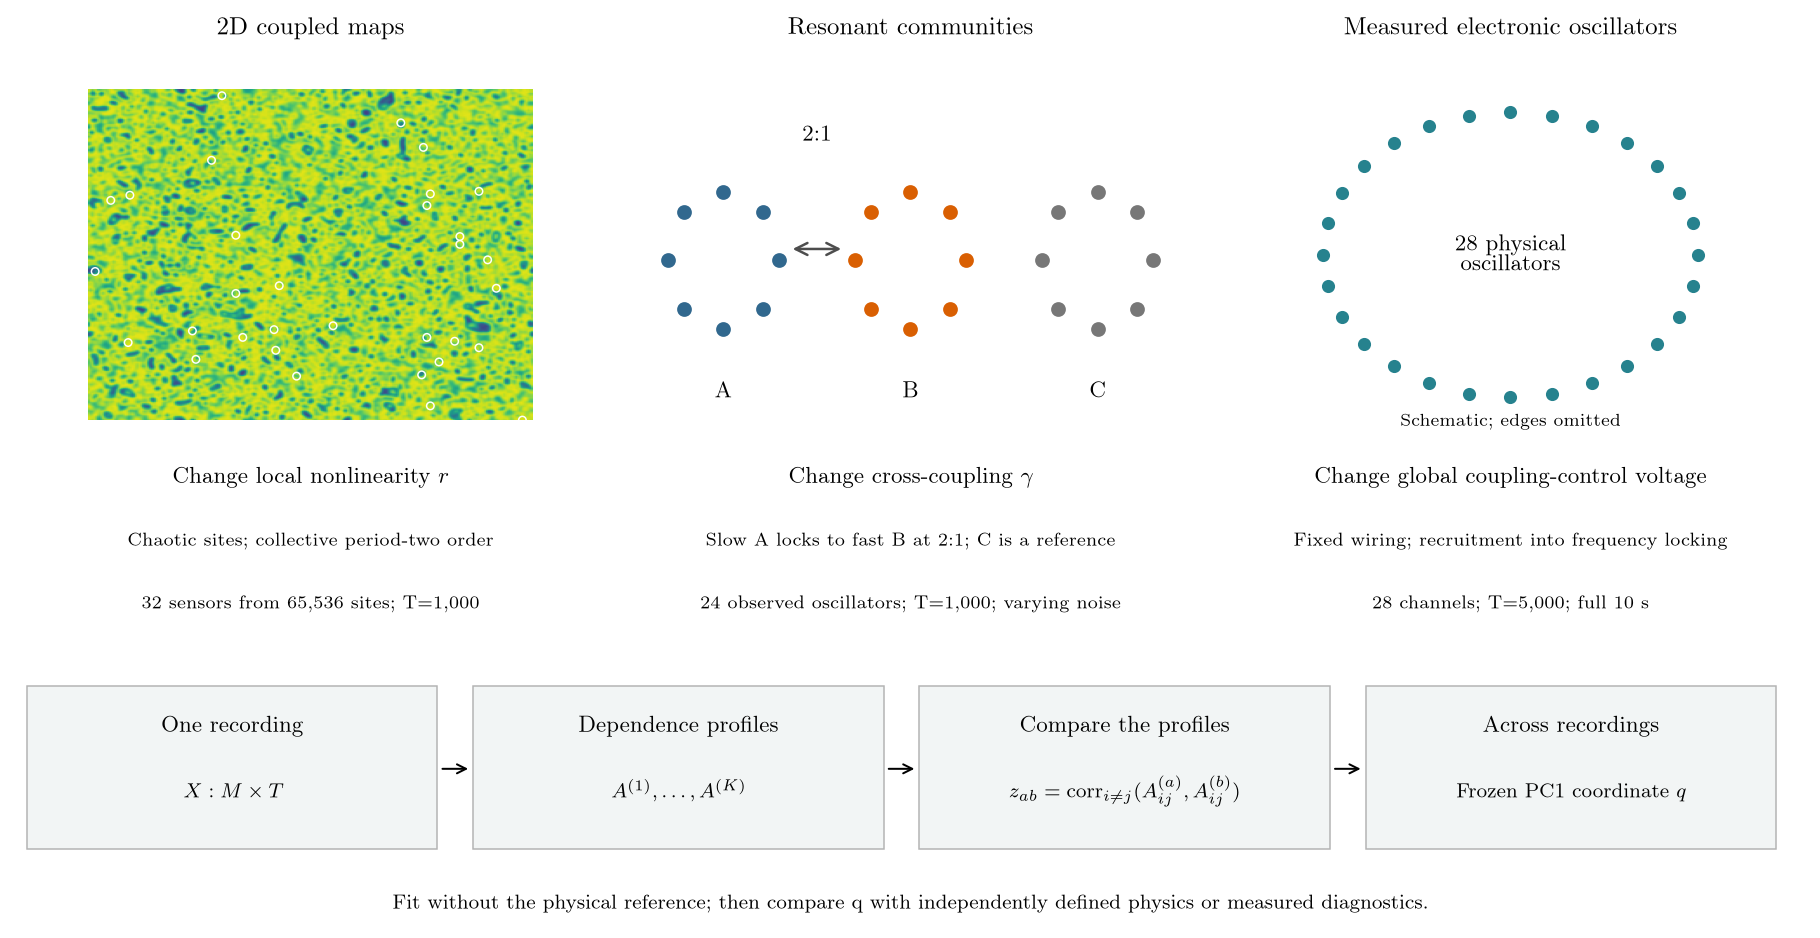

In [2]:
show(draw_overview(cml))

**Reading the composites:** illustrative physics/observed portraits → MTS snapshots → frozen readouts across control settings. Black is the physical reference; teal is the readout. Heatmaps use full-record, per-channel robust scaling with shared limits within each system; cropping is display-only. Synthetic bands show 10–90% seed variation, not confidence intervals. Hardware has no replicate bands. Dual axes retain original units and independent ranges.

Each study retains its own frozen centred PCA and eligibility rules; CML q is in development-score SD units. Models, signs and extraction versions are not pooled or retuned.

## 1 · CML2D: collective period-two order

A periodic **256×256 lattice** of chaotic logistic maps has fixed four-neighbour coupling g=.2. Increasing local nonlinearity r merges the alternating global-mean levels. Observe **32 dispersed sites × 1,000 steps**. The reference $Q=\langle|\bar x(2t+1)-\bar x(2t)|\rangle$ uses a disjoint million-step window. [Model and order parameter](https://arxiv.org/abs/nlin/0605004).

**Test:** recover collective order from sparse dependence profiles. Fit on four development seeds; confirm on **32 fresh seeds × 17 controls**. Upper examples use a fixed original held seed; bottom curves use independent confirmation. The dotted infinite-size boundary is a numerical reference.

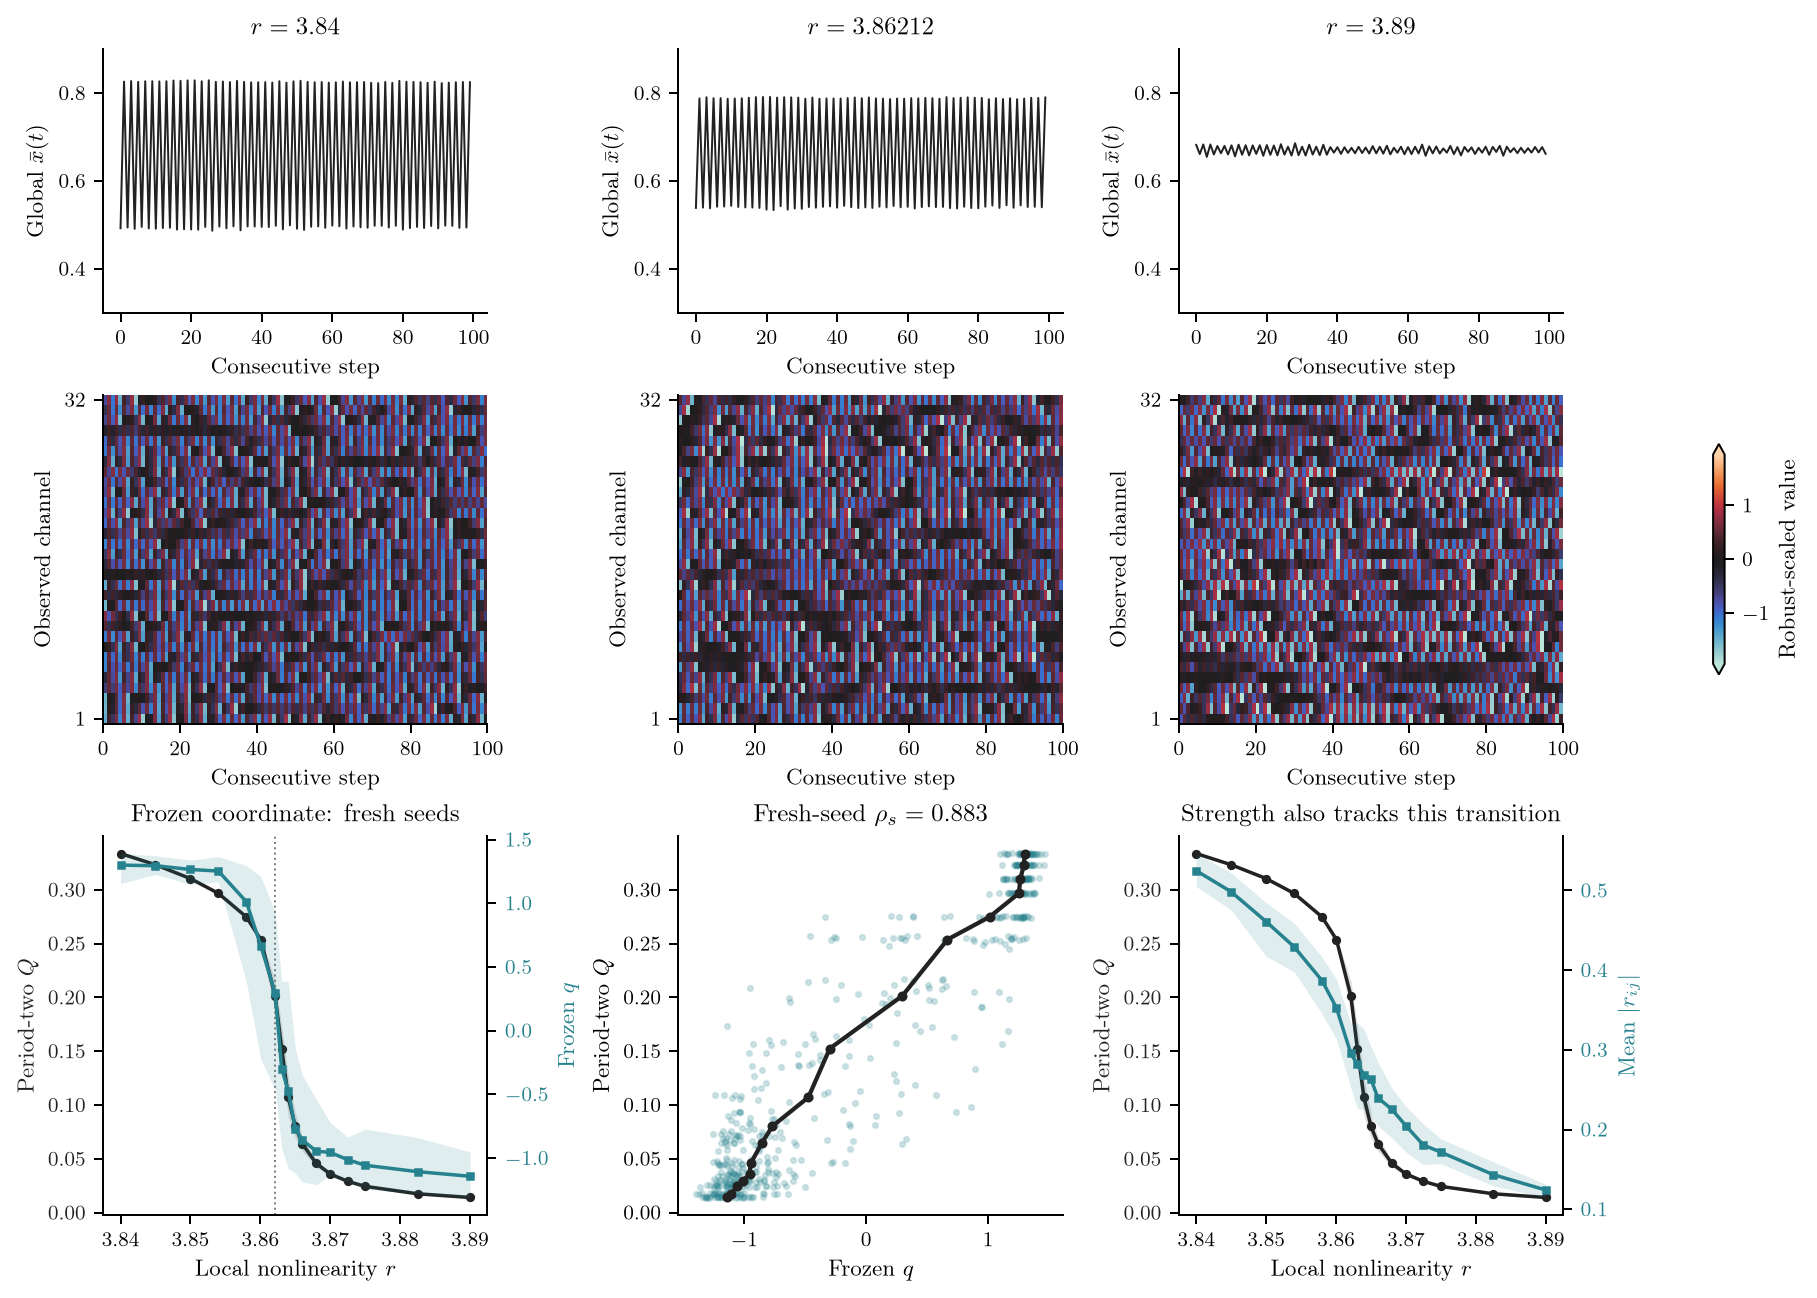

In [3]:
show(draw_cml(cml))

Frozen q tracks Q (ρ=.883); mean absolute Pearson is stronger (.966). This demonstrates transition sensitivity, not baseline superiority.

## 2 · Noisy harmonic locking: prioritise dynamics over recording quality

Three eight-oscillator communities: **slow A and fast B couple resonantly; C is a reference**. Increase cross-coupling γ toward 2:1 locking. Observe **24 channels × 1,000 samples**. Each recording receives independent sensor noise with amplitude η∼U[.3,.9], independent of γ; η is shared across channels, noise realisations are not. [Underlying model](https://arxiv.org/abs/1502.06193), modified by finite populations, noise and community C.

**Test:** does PC1 prioritise locking over noise? Fit eight seeds, evaluate eight held seeds at each of **21 controls**. Q measures harmonic phase alignment in a disjoint future window. Displayed noisy observations are selected nearest η=.6 at γ=0/.10/.20, without consulting Q/q. The dotted threshold is an approximate reduced-model reference.

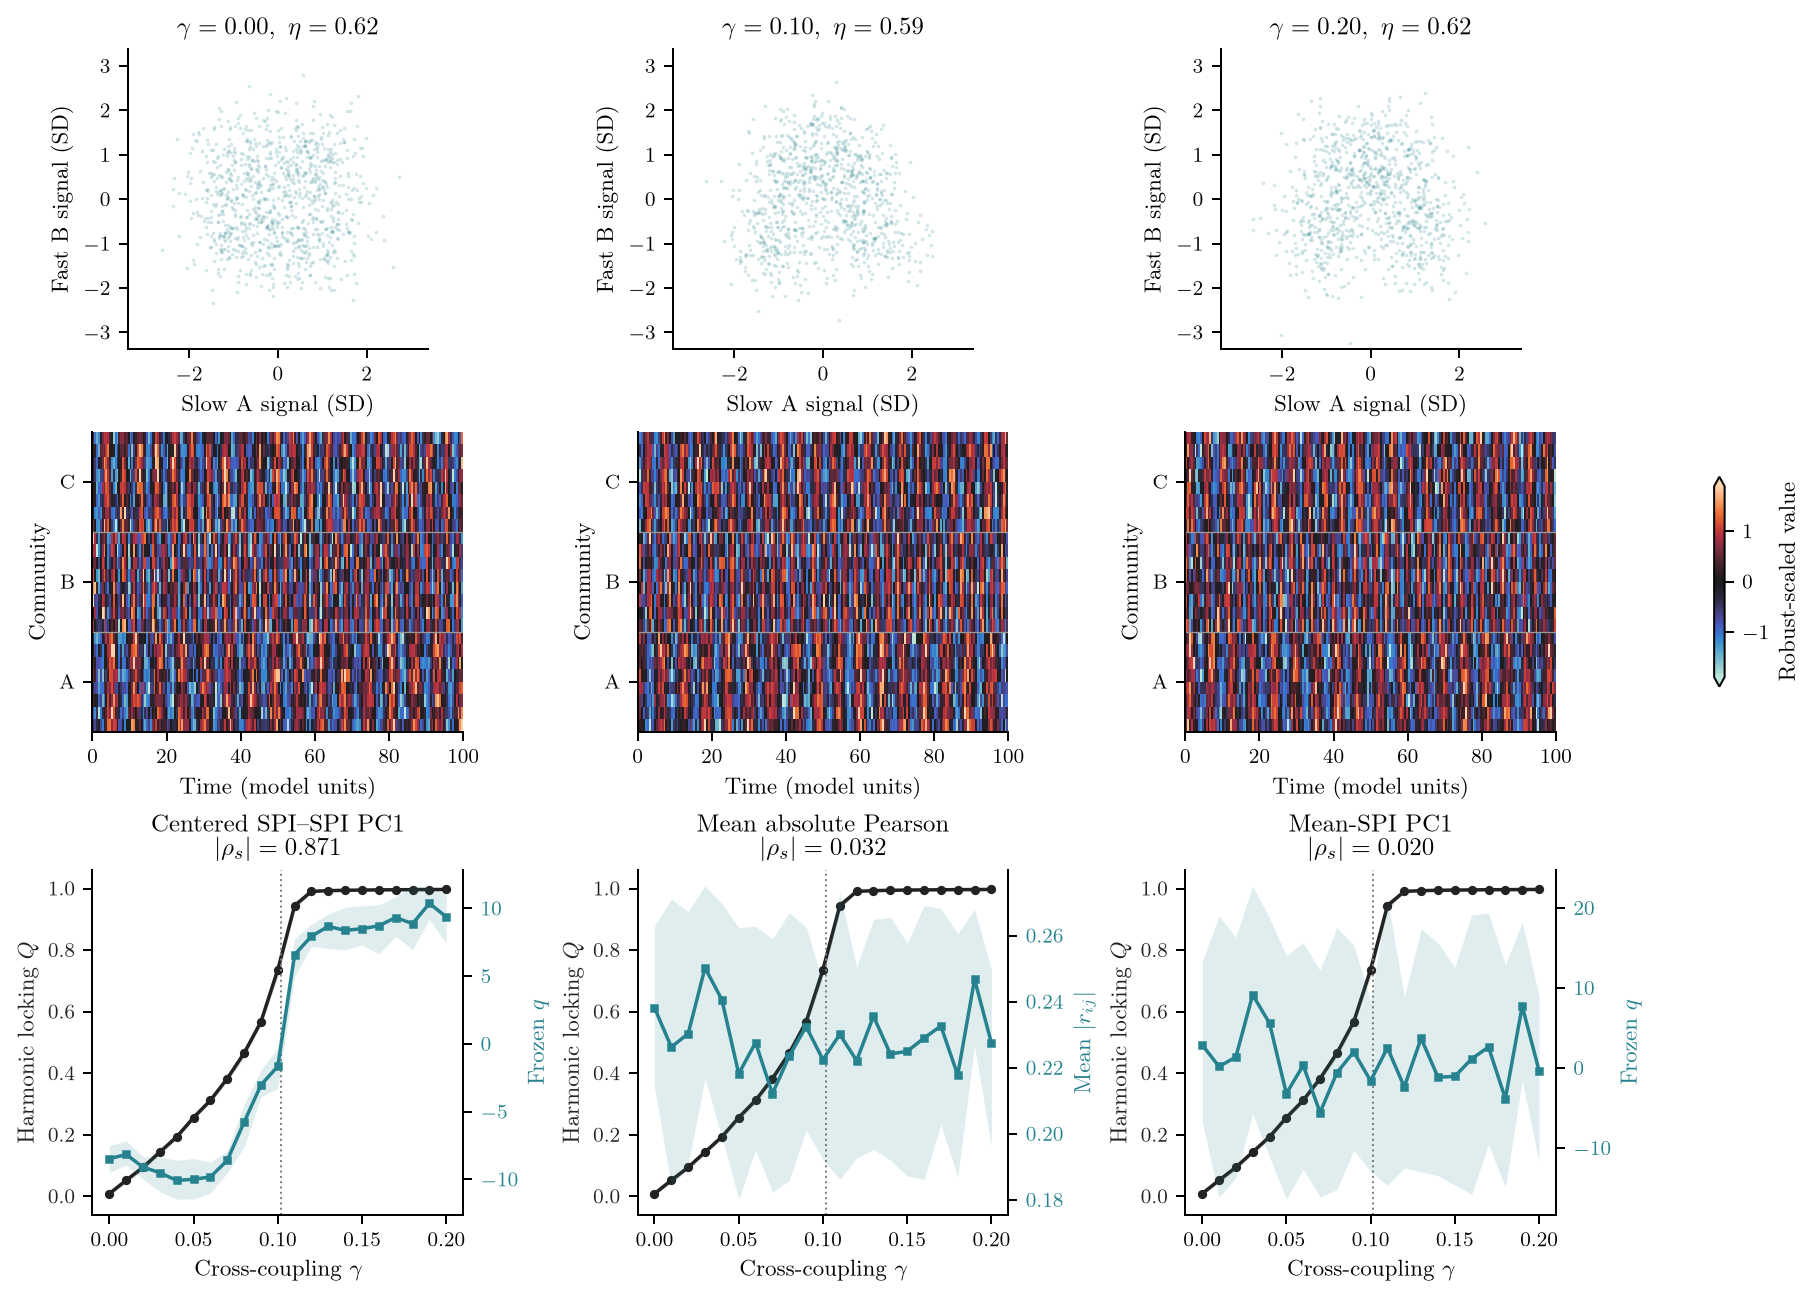

In [4]:
show(draw_locking(locking))

Held association with Q: **.871 / .032 / .020** for SPI–SPI PC1 / mean absolute Pearson / mean-SPI PC1. Locking information remains in later mean-SPI components. Existing M48 confirmation gives .855/.133/.115.

## 3 · Hardware: measured locking and transfer across wiring

**28 analogue Rössler-like oscillators**, fixed diffusive coupling law and wiring within each sweep. Settings vary the global coupling-control voltage. From 701 settings each in [ER](https://zenodo.org/records/17451096) and [small-world](https://zenodo.org/records/17451530), use **29 ER + 16 small-world records**, retaining all channels and 10 s, anti-aliased to **500 Hz / T=5,000** after fidelity checks. Refinements target physically observed changes.

**Test:** fit ER alone, freeze, project small-world without imputation. All 45 version-consistent r9 extractions already exist. Reference: channel-frequency range in the 90–140 Hz component over the central 9 s; no universal Q is assumed. Snapshots focus on ER locking: relative phases use channel 1 and start at zero for display; heatmaps show unfiltered observations.

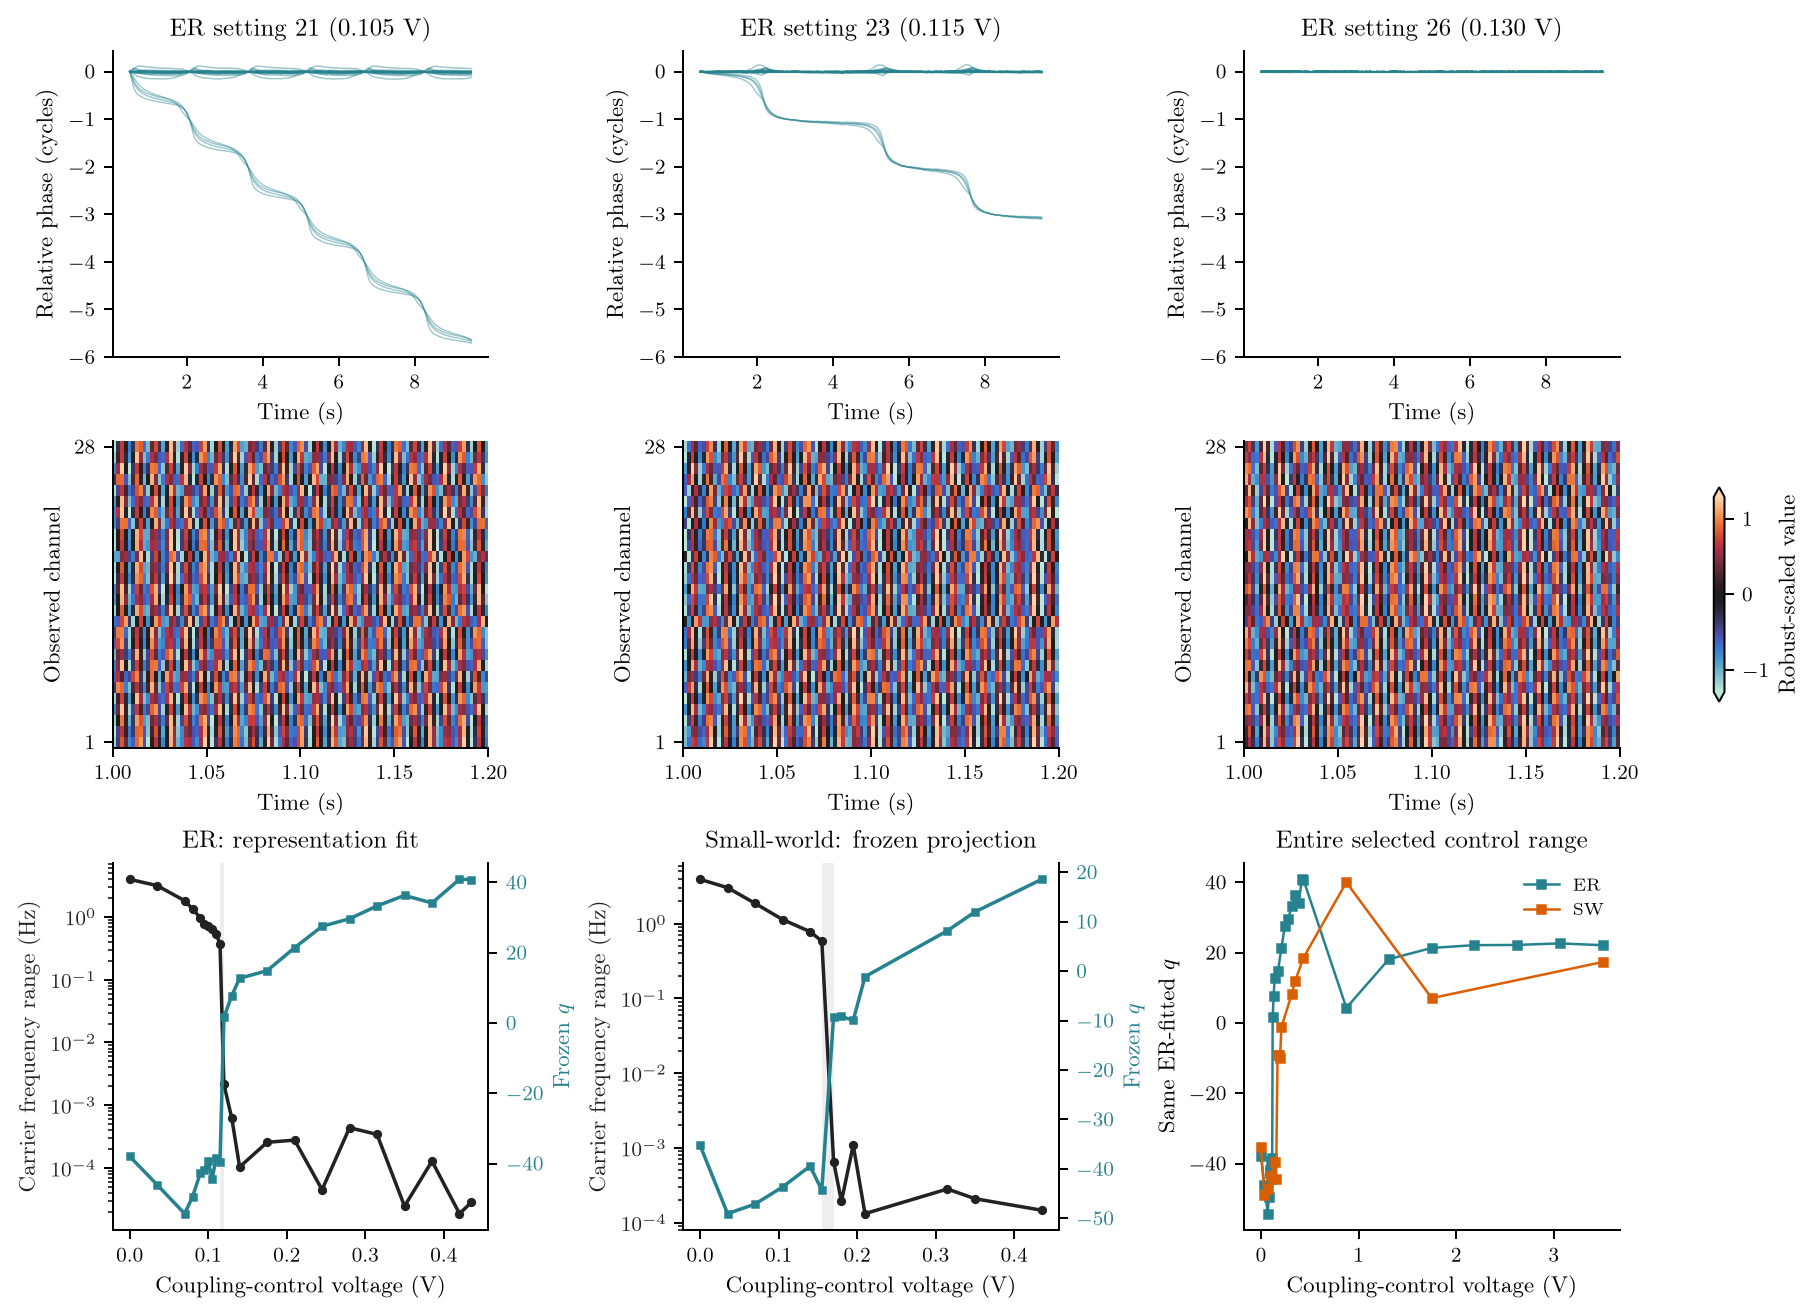

In [5]:
show(draw_hardware(hardware))

Largest adjacent PC1 changes coincide with locking: **ER 23→24** and **small-world 31→34**. ER PC1 explains 45.2%. This is exploratory cross-wiring transfer; PCA ordering depends on control sampling.

**Why does q change?** Kernel stochastic interaction × IDS reverses **+.534→−.905 ER; +.712→−.881 small-world**. The coherent core already has negative agreement before locking. Coloured edges show recruitment of previously less-coherent pairs, supported by bandwidth/window checks; the strong reversal remains estimator-family dependent.

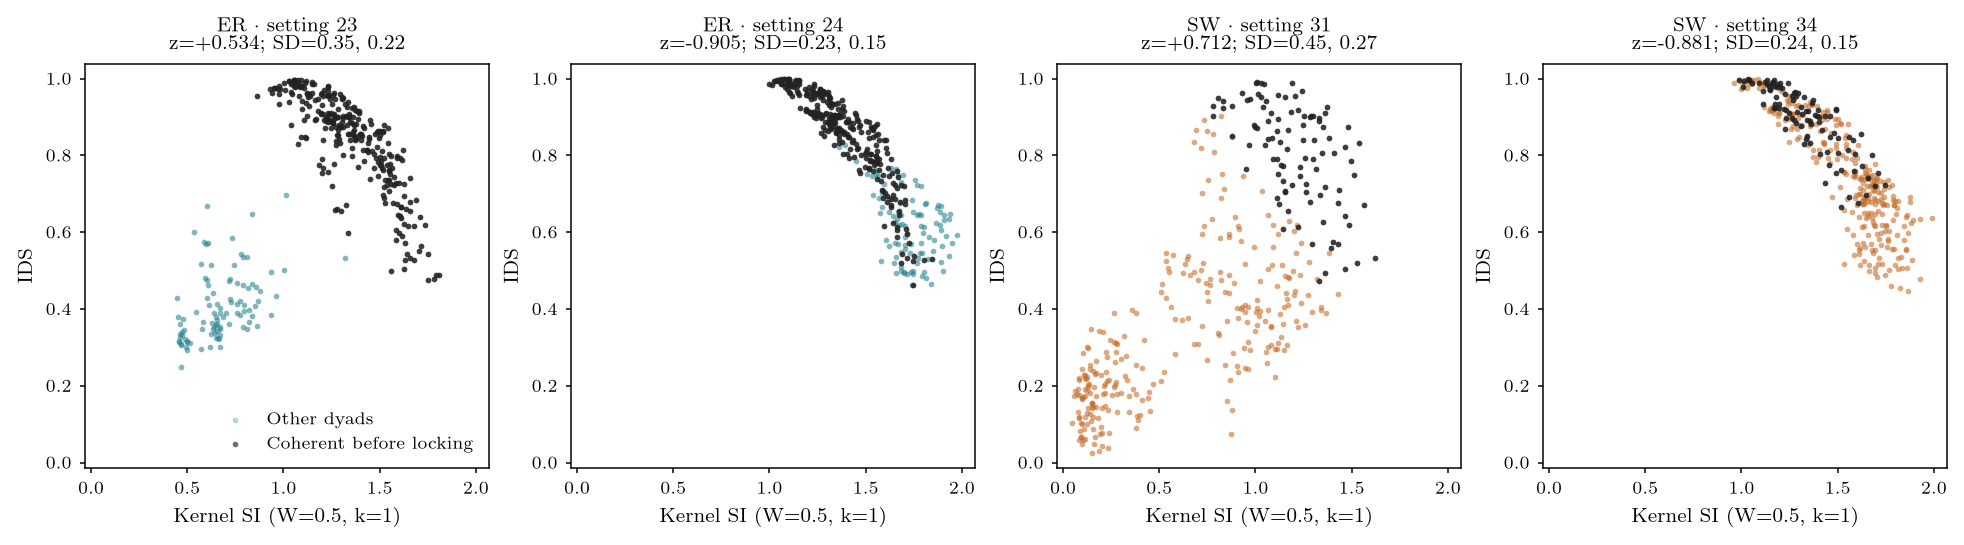

In [6]:
show(draw_hardware_edges(hardware))

Stochastic interaction includes instantaneous and temporal conditional dependence; it is not pure causal flow. A separately calibrated Pearson 2 ms × 20 ms feature explains spectral-profile organisation and distinguishes ER states at nearly identical mean Pearson strength; its fixed explanation passes 40/45 records. [Calibration, transfer and exceptions](../../../empirical/hardware_pilot/notebooks/hardware-pilot-calibrate.ipynb).

The studies establish complementary evidence: collective-transition sensitivity, prioritisation under a specified nuisance, and a physically interpretable measured analogue. No new extraction or model fitting was required.

In [7]:
summary = write_receipt(cml, locking, hardware)
display(summary.drop(columns='z_rho'))
print('Source hashes, snapshot selection and replay checks: results/order-parameter-inference/three-systems-261015/provenance.json')


,system,observed,samples,fit,evaluation,reference
0,CML2D,M32 / N65536,1000,4 development seeds × 9 controls,32 new seeds × 17 controls,Disjoint future period-two Q
1,Noisy 2:1 locking,M=N=24,1000,8 development seeds × 21 controls,8 held seeds × 21 controls,Disjoint future harmonic-locking Q
2,Hardware,M=N=28,5000,29 ER recordings,16 small-world recordings,Measured carrier dispersion; no known universal Q


Source hashes, snapshot selection and replay checks: results/order-parameter-inference/three-systems-261015/provenance.json
